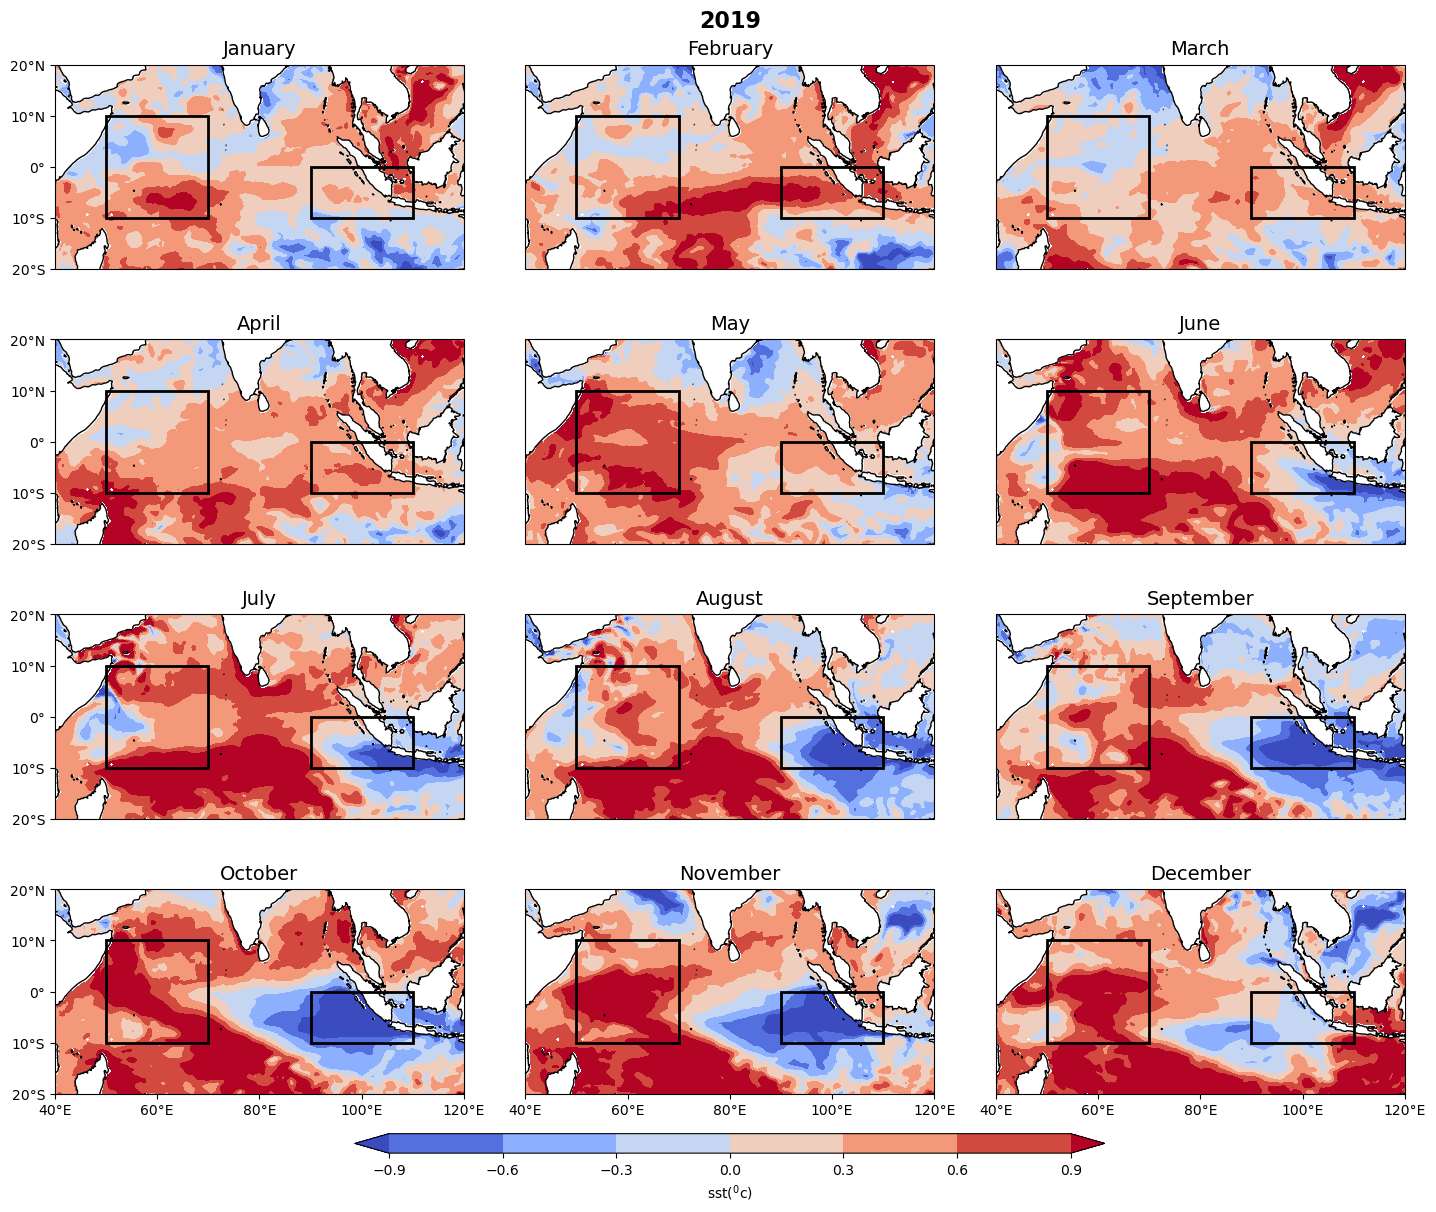

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
ds=xr.open_dataset('sst.nc')
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import calendar
import cartopy.mpl.ticker as cticker
import calendar
from matplotlib.patches import Rectangle
#print(ds)
#open netcdf file
ds = xr.open_dataset('sst.nc')
#get data sliced for the particular year
ds = ds.sel(time_counter = slice('1993','2021'),lat=slice(-20,20),lon=slice(40,120))
sst=ds['sosstsst'].values
#print(sst.shape)
#climatology
climatology= ds.groupby('time_counter.month').mean(dim='time_counter')
#print(climatology)
#anomaly
sst = sst.reshape(29,12,161,321)
anomaly = []
clevels=np.arange(-0.9,0.91,0.3)
for i in range(29):
    anomaly.append(sst[i] - climatology['sosstsst'].values)
#print(anomaly[0])
anomaly = np.array(anomaly)
anomaly = anomaly.reshape(29*12,161,321)
#print(anomaly)
    
fig,axs = plt.subplots(nrows = 4, ncols = 3, subplot_kw = {'projection':ccrs.PlateCarree()}, figsize = (15,13))
plt.subplots_adjust(left=0.05, right=0.95, bottom=0.113, top=0.91, wspace=0.15, hspace=0.3)
axs = axs.flatten()
yr=26
for j in range(12):
    cf = axs[j].contourf(ds['lon'], ds['lat'],anomaly[yr*12 + j],cmap='coolwarm',levels=clevels, extend='both', transform=ccrs.PlateCarree())
    axs[j].coastlines()
    # Define the xticks for longitude
    if j>=9:
       lon_range = np.arange(np.floor(ds['lon'].min()), np.ceil(ds['lon'].max()) + 1, 20)
       axs[j].set_xticks(lon_range, crs=ccrs.PlateCarree())
       lon_formatter = cticker.LongitudeFormatter()
       axs[j].xaxis.set_major_formatter(lon_formatter)
 
    # Define the yticks for latitude
    if j%3==0:
       lat_range = np.arange(np.floor(ds['lat'].min()), np.ceil(ds['lat'].max()) + 1,10)
       axs[j].set_yticks(lat_range, crs=ccrs.PlateCarree())
       lat_formatter = cticker.LatitudeFormatter()
       axs[j].yaxis.set_major_formatter(lat_formatter)
    #add month name to the plot
    month_name=calendar.month_name[j+1]
    axs[j].text(0.5,1.05,month_name,ha='center',transform=axs[j].transAxes,fontsize=14)
plt.suptitle(f'{1993+yr}',fontsize=16,fontweight='bold',y=0.95)
#define coordinate for the boxes 
box1=[50,70,-10,10]
box2=[90,110,-10,0]
for i in range(12):
    axs[i].add_patch(Rectangle((box1[0],box1[2]),box1[1]-box1[0],box1[3]-box1[2],fill=None,edgecolor='black',linewidth=2))
    axs[i].add_patch(Rectangle((box2[0],box2[2]),box2[1]-box2[0],box2[3]-box2[2],fill=None,edgecolor='black',linewidth=2))
cbar_ax = fig.add_axes([0.25, 0.07, 0.5, 0.015])  
cbar = fig.colorbar(cf,cax=cbar_ax, orientation='horizontal',label='sst($^0$c)')
cbar.ax.xaxis.set_label_position('bottom')  # Place the label at the top
cbar.ax.xaxis.set_label_coords(0.5,-1.5)  # Adjust the position of the label
plt.show()



array([[-0.6993084 , -0.72229004, -0.7507744 , ...,         nan,
                nan,         nan],
       [-0.70371246, -0.7137108 , -0.733387  , ..., -0.7365742 ,
        -0.6147747 , -0.55213356],
       [-0.696785  , -0.69425964, -0.70558167, ..., -0.72304344,
        -0.62451935, -0.58629227],
       ...,
       [-0.9366379 , -0.9735565 , -0.9339123 , ..., -0.36230087,
        -0.38600922, -0.40822983],
       [-0.9687195 , -0.9199257 ,         nan, ..., -0.29492188,
        -0.32679176, -0.34017944],
       [-0.9663658 , -0.86408615,         nan, ..., -0.21920586,
        -0.25824165, -0.27661705]], dtype=float32)

In [2]:
print(climatology)

<xarray.Dataset>
Dimensions:   (month: 12, lat: 161, lon: 321)
Coordinates:
  * lon       (lon) float64 40.0 40.25 40.5 40.75 ... 119.2 119.5 119.8 120.0
  * lat       (lat) float64 -20.0 -19.75 -19.5 -19.25 ... 19.25 19.5 19.75 20.0
  * month     (month) int64 1 2 3 4 5 6 7 8 9 10 11 12
Data variables:
    sosstsst  (month, lat, lon) float32 29.01 29.02 29.04 ... 26.27 26.35 26.42
Attributes:
    CDI:          Climate Data Interface version 1.9.2 (http://mpimet.mpg.de/...
    Conventions:  CF-1.4
    history:      Thu Feb 15 16:54:39 2024: cdo sellonlatbox,40,120,-40,25 OR...
    source:       ORAS5 - backward extension (ECMWF)
    institution:  European Centre for Medium-Range Weather Forecasts
    NCO:          netCDF Operators version 4.9.2 (Homepage = http://nco.sf.ne...
    title:        Monthly mean 2D Sea Surface fields
    reference:    https://www.ecmwf.int/en/research/climate-reanalysis/ocean-...
    CDO:          Climate Data Operators version 1.9.2 (http://mpimet.mpg.de/..